In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from kagglehub import KaggleDatasetAdapter

d:\Projects\video-game-sales-analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Set the path to the file you'd like to load
file_path = "vgsales.csv"


df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "gregorut/videogamesales",
    file_path,
)



C:\Users\gamez\AppData\Local\Temp\ipykernel_3620\3862125714.py:5: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


# Exploring DataSet

In [4]:
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01
16597,16600,Spirits & Spells,GBA,2003.0,Platform,Wanadoo,0.01,0.00,0.00,0.00,0.01


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16599 entries, 0 to 16598
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16599 non-null  str    
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), str(5)
memory usage: 1.4 MB


In [6]:
df.describe()

,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [7]:
df.isnull().sum()

Rank              0
Name              1
Platform          1
Year            272
Genre             1
Publisher        59
NA_Sales          1
EU_Sales          1
JP_Sales          1
Other_Sales       1
Global_Sales      1
dtype: int64

In [24]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.nunique()

Rank            16599
Name            11493
Platform           31
Year               39
Genre              12
Publisher         578
NA_Sales          409
EU_Sales          305
JP_Sales          244
Other_Sales       157
Global_Sales      623
dtype: int64

# Cleaning

In [10]:
df = df.dropna(subset=['Year'])
df = df.dropna(subset=['Publisher'])

In [11]:
df['Year'] = df['Year'].astype('int64')

In [13]:
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [14]:
df.isnull().sum()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

# Analysis

### Question 1: What are the lowest-selling video games in North America (NA)?

In [15]:
df.sort_values(by='NA_Sales').head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
15879,15882,PachiPara 3D,3DS,2011,Misc,Irem Software Engineering,0.0,0.00,0.02,0.0,0.02
12304,12306,Hisshou Pachinko*Pachi-Slot Kouryaku Series Vo...,PS2,2009,Misc,D3Publisher,0.0,0.00,0.06,0.0,0.06
16565,16568,Teslagrad,PSV,2015,Platform,Rain Games,0.0,0.01,0.00,0.0,0.01
12305,12307,Nicola Kanshuu: Model * Oshare Audition,DS,2010,Misc,Alchemist,0.0,0.00,0.06,0.0,0.06
16567,16570,Fujiko F. Fujio Characters: Great Assembly! Sl...,3DS,2014,Action,Namco Bandai Games,0.0,0.00,0.01,0.0,0.01


### Question 2: What are the top 6 best-selling video games in North America (NA)?

In [16]:
df.sort_values(by='NA_Sales',ascending=False).head(6)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
9,10,Duck Hunt,NES,1984,Shooter,Nintendo,26.93,0.63,0.28,0.47,28.31
5,6,Tetris,GB,1989,Puzzle,Nintendo,23.20,2.26,4.22,0.58,30.26
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00


### Question 3: What are the lowest-selling video games in Europe (EU)?

In [17]:
df.sort_values(by='EU_Sales').head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
16556,16559,Super Robot Taisen: Original Generation,GBA,2002,Role-Playing,Banpresto,0.01,0.0,0.00,0.0,0.01
16557,16560,Dramatical Murder Re:code,PSV,2014,Adventure,Nitroplus,0.00,0.0,0.01,0.0,0.01
16559,16562,Sugar + Spice! Anoko no Suteki na Nanimokamo,PS2,2008,Adventure,Alchemist,0.00,0.0,0.01,0.0,0.01
16560,16563,Hanasaku Manimani,PSV,2014,Adventure,5pb,0.00,0.0,0.01,0.0,0.01
16561,16564,Kanokon: Esuii,PS2,2008,Adventure,5pb,0.00,0.0,0.01,0.0,0.01


### Question 4: What are the top 6 best-selling video games in Europe (EU)?

In [18]:
df.sort_values(by='EU_Sales', ascending=False).head(6)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
10,11,Nintendogs,DS,2005,Simulation,Nintendo,9.07,11.00,1.93,2.75,24.76
16,17,Grand Theft Auto V,PS3,2013,Action,Take-Two Interactive,7.01,9.27,0.97,4.14,21.40
19,20,Brain Age: Train Your Brain in Minutes a Day,DS,2005,Misc,Nintendo,4.75,9.26,4.16,2.05,20.22


### Question 5: What are the lowest-selling video games in Japan (JP)?

In [19]:
df.sort_values(by='JP_Sales').head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.0,0.0,0.00,0.01
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.0,0.0,0.00,0.01
16592,16595,Plushees,DS,2008,Simulation,Destineer,0.01,0.0,0.0,0.00,0.01
16591,16594,Myst IV: Revelation,PC,2004,Adventure,Ubisoft,0.01,0.0,0.0,0.00,0.01
10417,10419,Winning Eleven: Pro Evolution Soccer 2007,X360,2006,Sports,Konami Digital Entertainment,0.09,0.0,0.0,0.01,0.10


### Question 6: What are the top 6 best-selling video games in Japan (JP)?

In [20]:
df.sort_values(by='JP_Sales', ascending=False).head(6)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
12,13,Pokemon Gold/Pokemon Silver,GB,1999,Role-Playing,Nintendo,9.00,6.18,7.20,0.71,23.10
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
6,7,New Super Mario Bros.,DS,2006,Platform,Nintendo,11.38,9.23,6.50,2.90,30.01
20,21,Pokemon Diamond/Pokemon Pearl,DS,2006,Role-Playing,Nintendo,6.42,4.52,6.04,1.37,18.36
26,27,Pokemon Black/Pokemon White,DS,2010,Role-Playing,Nintendo,5.57,3.28,5.65,0.82,15.32


### Question 7: Which video game genres generate the highest total global sales?

In [21]:
df.groupby('Genre')['Global_Sales'].sum().sort_values(ascending=False)

Genre
Action          1722.84
Sports          1309.24
Shooter         1026.20
Role-Playing     923.83
Platform         829.13
Misc             789.87
Racing           726.76
Fighting         444.05
Simulation       389.98
Puzzle           242.21
Adventure        234.59
Strategy         173.27
Name: Global_Sales, dtype: float64

### Question 8: Which gaming platforms have generated the highest total global sales?

In [22]:
df.groupby('Platform')['Global_Sales'].sum().sort_values(ascending = False)

Platform
PS2     1233.46
X360     969.60
PS3      949.35
Wii      909.81
DS       818.91
PS       727.39
GBA      305.62
PSP      291.71
PS4      278.10
PC       254.70
GB       254.42
XB       252.09
NES      251.07
3DS      246.27
N64      218.21
SNES     200.05
GC       197.14
XOne     141.06
2600      86.57
WiiU      81.86
PSV       61.60
SAT       33.59
GEN       28.36
DC        15.97
SCD        1.87
NG         1.44
WS         1.42
TG16       0.16
3DO        0.10
GG         0.04
PCFX       0.03
Name: Global_Sales, dtype: float64

### Question 9: Which platform has the most games and which sold the most?

In [32]:
platform_summary = df.groupby('Platform').agg(
    games=('Name', 'count'),
    total_sales=('Global_Sales', 'sum')
).sort_values('total_sales', ascending=False)

print(platform_summary)

          games  total_sales
Platform                    
PS2        2127      1233.46
X360       1234       969.60
PS3        1304       949.35
Wii        1290       909.81
DS         2131       818.91
PS         1189       727.39
GBA         786       305.62
PSP        1197       291.71
PS4         336       278.10
PC          938       254.70
GB           97       254.42
XB          803       252.09
NES          98       251.07
3DS         499       246.27
N64         316       218.21
SNES        239       200.05
GC          542       197.14
XOne        213       141.06
2600        116        86.57
WiiU        143        81.86
PSV         410        61.60
SAT         173        33.59
GEN          27        28.36
DC           52        15.97
SCD           6         1.87
NG           12         1.44
WS            6         1.42
TG16          2         0.16
3DO           3         0.10
GG            1         0.04
PCFX          1         0.03


### Question 10: What are the 10 best-selling games ever?

In [37]:
top10 = (
    df.groupby('Name')
      .agg(Total_Sales=('Global_Sales', 'sum'))
      .sort_values('Total_Sales', ascending=False)
      .head(10)
)
print(top10)

                                Total_Sales
Name                                       
Wii Sports                            82.74
Grand Theft Auto V                    55.92
Super Mario Bros.                     45.31
Tetris                                35.84
Mario Kart Wii                        35.82
Wii Sports Resort                     33.00
Pokemon Red/Pokemon Blue              31.37
Call of Duty: Modern Warfare 3        30.83
New Super Mario Bros.                 30.01
Call of Duty: Black Ops II            29.72


# Plotting

### Question 11: How are video game sales distributed across different genres and regions?

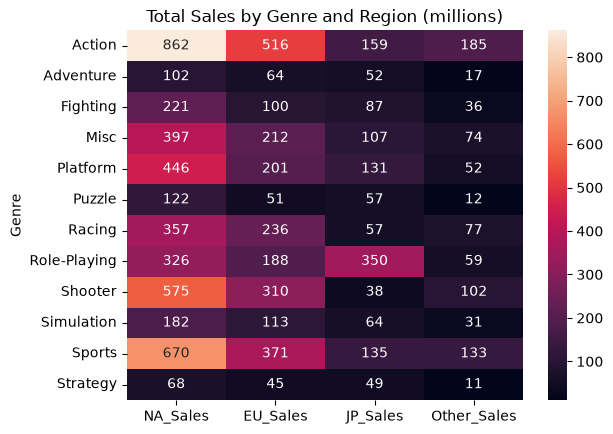

In [23]:
genre_region = df.groupby('Genre')[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']].sum()

sns.heatmap(genre_region,annot=True,fmt='.0f')
plt.title('Total Sales by Genre and Region (millions)')
plt.show()

### Question 12: What is the distribution of global sales across different genres?

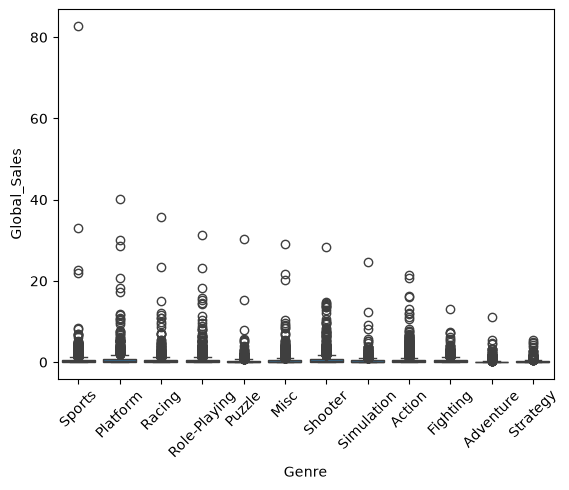

In [43]:
sns.boxplot(x='Genre', y='Global_Sales', data=df)
plt.xticks(rotation=45)
plt.show()

### Question13 : How did total global sales change from year to year, from the earliest year in the data up to 2010?

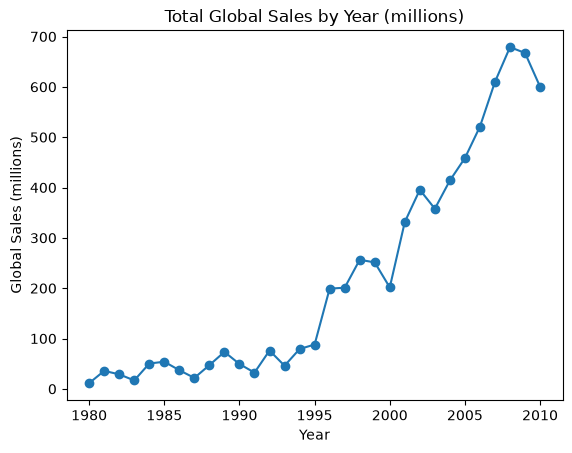

In [42]:
yearly_sales = df.groupby('Year')['Global_Sales'].sum()
yearly_sales = yearly_sales[yearly_sales.index <= 2010]

yearly_sales.plot(kind='line', marker='o')
plt.title('Total Global Sales by Year (millions)')
plt.xlabel('Year')
plt.ylabel('Global Sales (millions)')
plt.show()

### Question 14: Which region drives global sales most?

NA_Sales       0.941269
EU_Sales       0.903264
JP_Sales       0.612774
Other_Sales    0.747964
dtype: float64


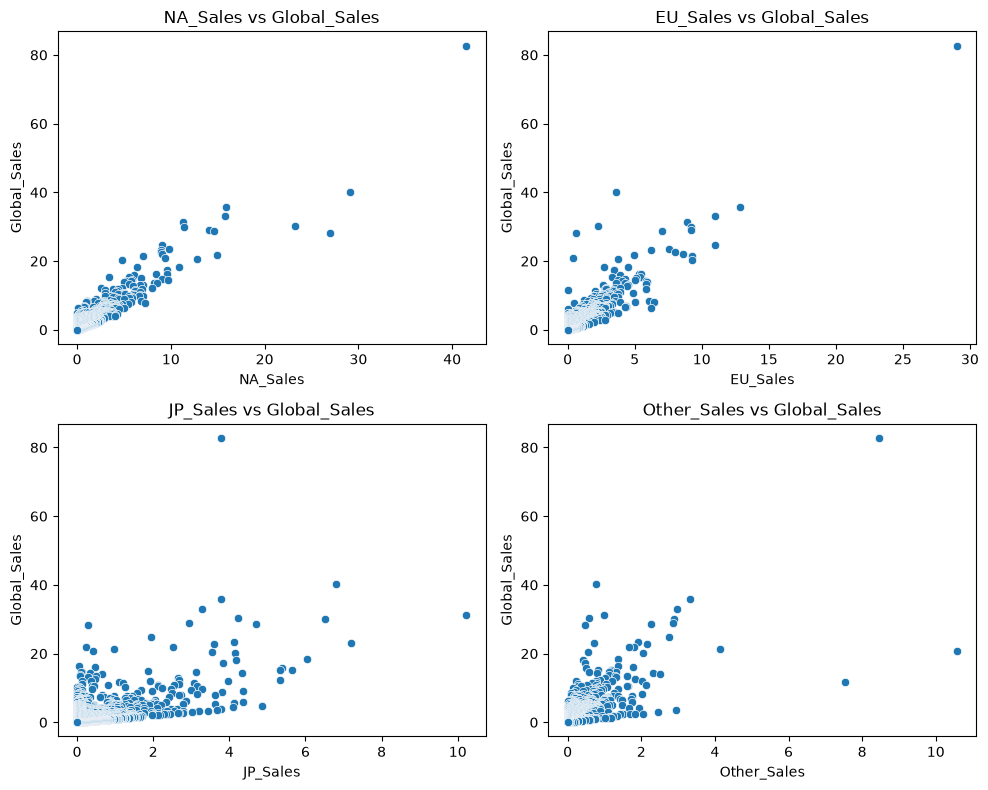

In [46]:
regions = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']

print(df[regions].corrwith(df['Global_Sales'].sort_values(ascending = False)))

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, col in zip(axes.flatten(), regions):
    sns.scatterplot(x=col, y='Global_Sales', data=df, ax=ax)
    ax.set_title(f'{col} vs Global_Sales')

plt.tight_layout()
plt.show()
